# Validation du solveur

Ancrage : Gayon, Talay-Değirmenci, Karaesmen & Örmeci (2009), *Optimal Pricing and
Production Policies of a Make-to-Stock System with Fluctuating Demand*, **PEIS** 23(2).

Ce notebook a deux parties, dont le **statut épistémique diffère** et qu'il ne faut pas
confondre :

| | portée | ce qui est établi |
|---|---|---|
| **3.1** | $N=2$, $K=0$, lost sales | reproduction de valeurs **publiées** (Tables 3-5, Figure 2) |
| **3.2** | $N>2$, $K>0$, backlog | **cohérence interne** : cas limites et propriétés structurelles |

Le papier ne couvre que le cas de la première ligne. Les extensions n'ont aucune
référence à reproduire : leur validation est donc plus faible, et le rapport final doit
le dire explicitement plutôt que de laisser croire à une vérification homogène.

Paramètres de référence (§5.3 du papier) : $\bar{\Lambda} = 1$, $a = 1$, $c = 0$, $h = 0.01$,
$q = 0.01$, $\mu = 0.11$, grille de prix au pas 0.01 (Appendix E).

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from dynamicpricer import validation as V

# Les résultats sont précalculés par `python -m dynamicpricer.validation` (quelques minutes).
if V.RESULTS_PATH.exists():
    results = json.loads(V.RESULTS_PATH.read_text(encoding="utf-8"))
    print(f"Résultats chargés depuis {V.RESULTS_PATH.name}")
else:
    results = V.run_all()
    print("Résultats recalculés")

pd.set_option("display.width", 120)

Résultats chargés depuis validation_results.json


## 1. Validation externe

### Table 4: niveaux de base-stock

Les base-stocks sont des **entiers** : contrairement aux profit gains, l'exactitude y est
atteignable, et c'est donc le test le plus discriminant des trois tables. Un écart d'une
seule unité signalerait une erreur de modélisation.

In [2]:
t4 = pd.DataFrame(results["table_4"])
display(t4)
print(f"{t4['exact'].sum()} / {len(t4)} base-stocks reproduits exactement")

,eps,quantity,computed,published,exact
0,0.0,s_s,8,8,True
1,0.0,s_sb,8,8,True
2,0.0,s_sp,"[8, 8]","[8, 8]",True
3,0.0,s_edp,"[8, 8]","[8, 8]",True
4,0.0,s_dp,"[17, 17]","[17, 17]",True
5,0.3,s_s,7,7,True
6,0.3,s_sb,8,8,True
7,0.3,s_sp,"[6, 11]","[6, 11]",True
8,0.3,s_edp,"[7, 9]","[7, 9]",True
9,0.3,s_dp,"[12, 20]","[12, 20]",True


20 / 20 base-stocks reproduits exactement


### Table 3: profit gains

Le papier ne publie qu'une décimale, donc son propre arrondi vaut déjà $\pm 0.05$ point. La
tolérance retenue est de 0.3 point de pourcentage.

In [3]:
t3 = pd.DataFrame(results["table_3"])
display(t3)
print(f"écart maximum : {t3['gap_pp'].abs().max():.2f} point de %")

,eps,quantity,computed,published,gap_pp
0,0.0,"PG_sb,s",0.00,0.0,0.00
1,0.0,"PG_sp,s",-0.00,0.0,-0.00
2,0.0,"PG_edp,s",-0.00,0.0,-0.00
3,0.0,"PG_dp,s",2.20,2.2,0.00
4,0.3,"PG_sb,s",1.57,1.5,0.07
5,0.3,"PG_sp,s",0.05,0.0,0.05
6,0.3,"PG_edp,s",1.58,1.5,0.08
7,0.3,"PG_dp,s",3.94,3.8,0.14
8,0.6,"PG_sb,s",7.26,7.3,-0.04
9,0.6,"PG_sp,s",0.46,0.5,-0.04


écart maximum : 0.14 point de %


**Lecture.** Le biais est systématiquement positif et de l'ordre de l'arrondi de la
source. L'enseignement de fond est reproduit : les profit gains croissent avec la
variabilité $\varepsilon$, et $PG^{\text{edp},s}$ reste très proche de $PG^{\text{dp},s}$ c'est-à-dire que
**la tarification dépendante de l'environnement capte l'essentiel du bénéfice de la
tarification dynamique**, pour un coût opérationnel bien moindre.

### Table 5: prix optimaux

Pour DP, l'intervalle $(\underline{p}_e, \bar{p}_e)$ est pris sur les **états récurrents**
$0 \le x \le \max_e s_e$, comme l'indique la légende de la Table 5. Le prix en $x = 0$ est
exclu : la demande y est perdue, le prix n'a donc aucun effet.

In [4]:
t5 = pd.DataFrame(results["table_5"])
display(t5)
outliers = t5[t5["gap"] > V.PRICE_TOLERANCE]
print("valeurs hors tolérance :")
display(outliers)

,eps,quantity,computed,published,gap
0,0.0,p_s,0.79,0.79,0.000
1,0.0,p_sb,"[0.79, 0.79]","[0.79, 0.79]",0.000
2,0.0,p_sp,0.79,0.79,0.000
3,0.0,p_edp,"[0.79, 0.79]","[0.79, 0.79]",0.000
4,0.0,p_dp_L,"[0.502, 0.853]","[0.5, 0.85]",0.003
5,0.0,p_dp_H,"[0.502, 0.853]","[0.5, 0.85]",0.003
6,0.3,p_s,0.78,0.78,0.000
7,0.3,p_sb,"[0.74, 0.82]","[0.74, 0.82]",0.000
8,0.3,p_sp,0.78,0.78,0.000
9,0.3,p_edp,"[0.74, 0.82]","[0.74, 0.82]",0.000


valeurs hors tolérance :


,eps,quantity,computed,published,gap
16,0.6,p_dp_L,"[0.31, 0.75]","[0.33, 0.75]",0.020
23,0.8,p_dp_H,"[0.502, 0.883]","[0.51, 0.99]",0.107


**Deux écarts subsistent, tous deux sur DP.**

| | papier | solveur |
|---|---|---|
| $\varepsilon = 0.6$, $p^{\text{dp}}_L$ (min) | 0.33 | 0.31 |
| $\varepsilon = 0.8$, $\bar{p}^{\text{dp}}_H$ (max) | 0.99 | 0.88 |

Le premier (0.33) figure aussi dans la version de conférence de 2006 ; le solveur applique la
définition du papier (minimum sur les états récurrents, atteint au stock 22) et l'écart reste
inexpliqué. Pour le second, la version de conférence de 2006 publie **0.88**, valeur que le solveur
retrouve (0.883), alors que la version de revue publie 0.99 et en tire un écart de prix de 0.8 dans
son texte : la source diverge d'une version à l'autre. Le solveur ne retrouve 0.99 nulle part (le
prix maximal de DP reste à 0.883 pour $\varepsilon$ de 0.7 à 0.95) et les résultats sont insensibles
à la troncature ($m$ de 60 à 400) et à la tolérance ($10^{-5}$ à $10^{-11}$).

Ces deux écarts sont **figés dans la suite de tests** : si une évolution du solveur les
faisait disparaître ou en créait d'autres, le test le signalerait au lieu de les laisser
se fondre dans le décor.

### Figure 2: profit gains en fonction du taux de service

À $\varepsilon = 0.8$. La figure ne fait intervenir ni S ni SB.

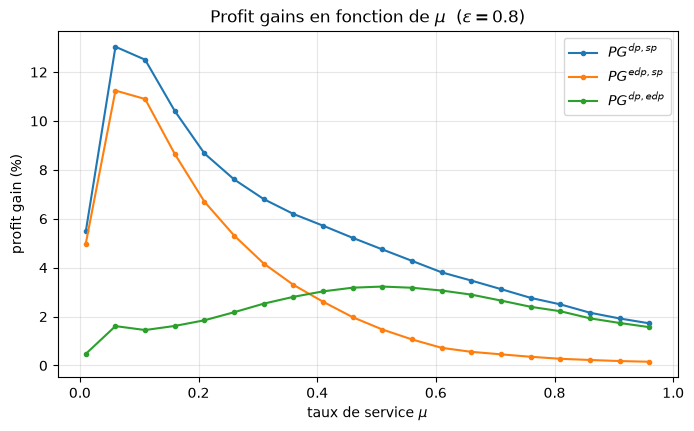

In [5]:
fig2 = pd.DataFrame(results["figure_2"])
fig, ax = plt.subplots(figsize=(8, 4.5))
for col, label in [("PG_dp_sp", "$PG^{dp,sp}$"),
                   ("PG_edp_sp", "$PG^{edp,sp}$"),
                   ("PG_dp_edp", "$PG^{dp,edp}$")]:
    ax.plot(fig2["mu"], fig2[col], marker="o", ms=3, label=label)
ax.set_xlabel("taux de service $\\mu$")
ax.set_ylabel("profit gain (%)")
ax.set_title("Profit gains en fonction de $\\mu$  ($\\varepsilon = 0.8$)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Lecture.** Trois traits de la Figure 2 du papier sont reproduits :

1. les gains sont **non monotones** en $\mu$, ils culminent à capacité intermédiaire.
   À capacité très faible le stock moyen est quasi nul et l'on vend au prix fort en
   permanence ; à capacité abondante la politique de réapprovisionnement suffit à
   absorber les fluctuations. La tarification ne vaut que dans l'entre-deux ;
2. $PG^{\text{dp},\text{sp}}$ dépasse nettement $PG^{\text{edp},\text{sp}}$, mais l'écart entre les deux c'est-à-dire
   $PG^{\text{dp},\text{edp}}$ reste **marginal** ($< 3.3$ % sur tout le balayage, §5.3.1) ;
3. au-delà de $\mu \approx 0.6$, tous les gains retombent sous 4 %.

C'est l'argument central du papier : le gain vient de l'**adaptation à l'environnement**,
pas de l'adaptation au niveau de stock.

### Propriétés structurelles

Reproduire des chiffres ne suffit pas : les théorèmes du papier prédisent des propriétés
**qualitatives** que le solveur doit exhiber. Elles sont plus robustes que les valeurs
numériques, et un solveur juste par accident les violerait.

In [6]:
st = pd.DataFrame(results["structural"])
display(st)
bools = st.select_dtypes(include="bool")
assert bools.all().all(), "propriété structurelle en défaut"
print("Lemme 1 (concavité), Théorème 2 (prix décroissants en stock),")
print("Théorème 3 (base-stocks ordonnés) et §5.3.2 : vérifiés sur les 4 instances.")

,eps,profit_ordering,value_function_concave,dp_prices_non_increasing,base_stock_ordered,dp_stores_most,note
0,0.0,True,True,True,True,True,"s^s, s^sb <= s^dp_L"
1,0.3,True,True,True,True,True,"s^s, s^sb <= s^dp_L"
2,0.6,True,True,True,True,True,"s^s, s^sb <= s^dp_L"
3,0.8,True,True,True,True,True,s^sb=4 > s^dp_L=3


Lemme 1 (concavité), Théorème 2 (prix décroissants en stock),
Théorème 3 (base-stocks ordonnés) et §5.3.2 : vérifiés sur les 4 instances.


#### Une exception à une observation du papier, mise au jour par la reproduction

Le §5.3.2 observe, dans toutes les expériences, que $s^{\varphi}_e \le s^{\text{dp}}_e$ pour $\varphi \in \{\text{s}, \text{sb}, \text{sp}, \text{edp}\}$, c'est-à-dire que la
flexibilité de DP l'autorise à stocker davantage que toutes les autres stratégies. La
colonne `note` ci-dessus montre que **la Table 4 du papier fait elle-même exception** à
$\varepsilon = 0.8$ : elle y publie $s^{\text{sb}} = 4$ et $s^{\text{dp}}_L = 3$.

Le solveur reproduit ces deux valeurs **exactement** (elles font partie des 20 sur 20
de la Table 4) donc l'exception ne vient pas du calcul.

L'explication tient à la classification de la Table 1 : S et SB n'ont qu'**un seul**
base-stock, compromis entre les environnements, qui n'a aucune raison de rester sous le
seuil que DP retient dans l'environnement le plus faible. La propriété n'est naturelle
que pour les stratégies dont le base-stock dépend de l'environnement, SP et EDP où
elle est vérifiée sur les quatre instances. La vérification programmatique a donc été
restreinte à ce périmètre, et le constat figé dans un test dédié.

## 2. Cohérence interne des extensions

**Aucune de ces trois extensions n'a de référence publiée à reproduire.** Ce qui suit
atteste que le solveur est cohérent avec lui-même, pas que le modèle est correct au
regard d'une source externe. C'est une garantie réellement plus faible.

| extension | cas limite | ce qu'il établit |
|---|---|---|
| $N > 2$ | dédoubler l'environnement H dans un modèle à 3 états | le cas $N=2$ est bien un cas particulier |
| $K > 0$ | $K = 0$ | le modèle à mise en route redonne **exactement** le modèle de base |
| backlog | $b \to \infty$ | le backlog converge vers le comportement lost-sales |

In [7]:
ext = pd.DataFrame(results["extensions"])
display(ext)

,case,computed,reference,gap,detail
0,N>2 : H dédoublé reproduit N=2,0.069422,0.069422,0.000000e+00,"s(N=3)=(7, 22, 22) vs s(N=2)=(7, 22)"
1,K=0 : le modèle à mise en route redonne le mod...,0.069423,0.069423,0.000000e+00,"bande=((7, 7), (22, 22)) vs base-stock=(7, 22)"
2,b→∞ : le backlog converge vers lost sales,0.069422,0.069422,3.500000e-08,"s=(7, 22) vs (7, 22)"


**Limite de validation, à reprendre telle quelle dans toute présentation du projet.**

Le périmètre du projet dépasse celui du papier de référence sur trois points, et ces
trois points ne sont **pas** validés au même niveau que le cœur du modèle :

- $N > 2$ : les opérateurs $T_0$, $T_2$, $T_\lambda$ sont génériques en $N$ et le papier les
  écrit ainsi, mais la Condition 1 (monotonicité des base-stock) n'est automatique que
  pour un processus de naissance-mort. Au-delà, elle est vérifiée explicitement sur la
  matrice de transition (`Problem.satisfies_condition_1`) ;
- $K > 0$ : le papier suppose explicitement « no set-up cost ». Le modèle retenu ici 
  (coût de redémarrage du serveur, état augmenté $\sigma$) a été **redérivé**, et sa politique
  optimale est une bande d'hystérésis, non un $(s, S)$ au sens de Chen & Simchi-Levi ;
- backlog : le papier suppose explicitement « lost sales ». L'extension à $x \in \mathbb{Z}$ avec
  coût de pénurie a également été redérivée.

Aucune Table ni Figure du papier ne peut servir de référence à ces trois volets.